In [1]:
# Import library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Masukkan dataset ke Dataframe df
df = pd.read_csv('CC GENERAL.csv')

# Cek missing data & Data types bukan numerik
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [2]:
# Cek baris 5 data teratas
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
# 1. Buat salinan dataframe dan hapus kolom CUST_ID (bukan numerik)
df_clean = df.drop(columns=['CUST_ID'])

# 2. Isi missing values pada CREDIT_LIMIT dan MINIMUM_PAYMENTS dengan median
df_clean['CREDIT_LIMIT'] = df_clean['CREDIT_LIMIT'].fillna(df_clean['CREDIT_LIMIT'].median())
df_clean['MINIMUM_PAYMENTS'] = df_clean['MINIMUM_PAYMENTS'].fillna(df_clean['MINIMUM_PAYMENTS'].median())

# Pastikan sudah tidak ada missing values
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [4]:
# Cek baris 5 data teratas dan satuan data numerik
df_clean.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,312.343947,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [5]:
# Cek satuan data numerik tiap kolom/fitur
df_clean.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.282473,1733.143852,844.906767,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.646702,2895.063757,2332.792322,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,170.857654,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,788.713501,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [6]:
# Standardisasi seluruh kolom/fitur numerik ke satuan yang selaras
# Tujuannya untuk mencegah dominasi kolom dalam perhitungan akibat satuan yang besar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)

In [7]:
# Cek mean dan std masing2 kolom/fitur yang sudah distandarisasi
print("Rata-rata tiap kolom:", X_scaled.mean(axis=0).round(2))
print("Standar deviasi tiap kolom:", X_scaled.std(axis=0).round(2))

Rata-rata tiap kolom: [ 0.  0.  0.  0.  0.  0. -0. -0.  0.  0. -0. -0.  0. -0.  0.  0.  0.]
Standar deviasi tiap kolom: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


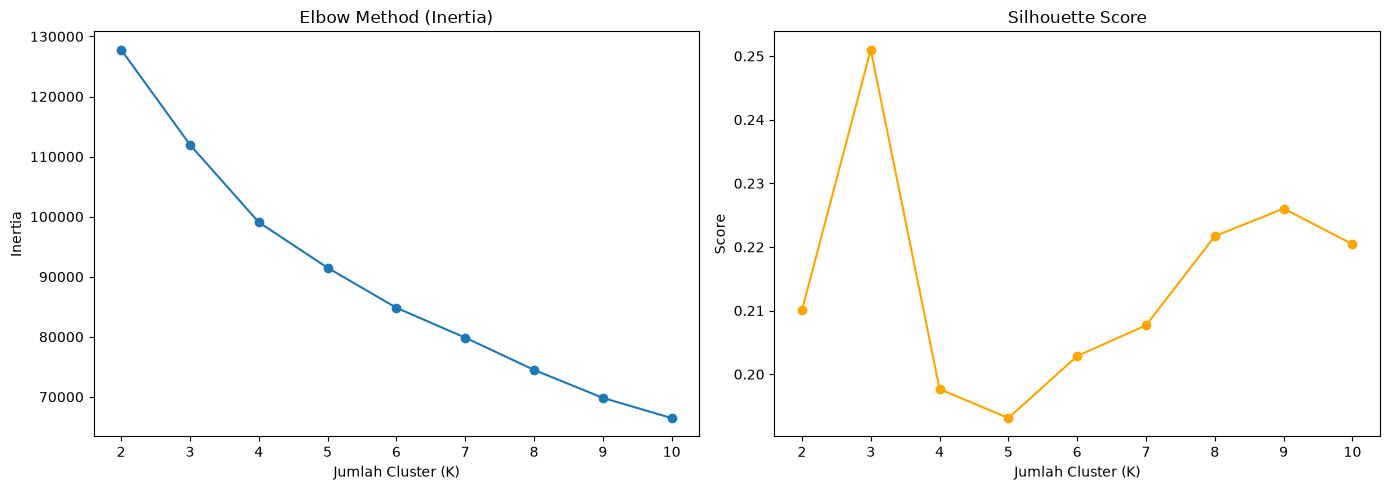

In [8]:
# Buat Grafik Plot Elbow Method & Silhouette Score untuk memutuskan jumlah Cluster

inertia = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(K_range, inertia, marker='o')
ax[0].set_title('Elbow Method (Inertia)')
ax[0].set_xlabel('Jumlah Cluster (K)')
ax[0].set_ylabel('Inertia')

ax[1].plot(K_range, sil_scores, marker='o', color='orange')
ax[1].set_title('Silhouette Score') 
ax[1].set_xlabel('Jumlah Cluster (K)')
ax[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

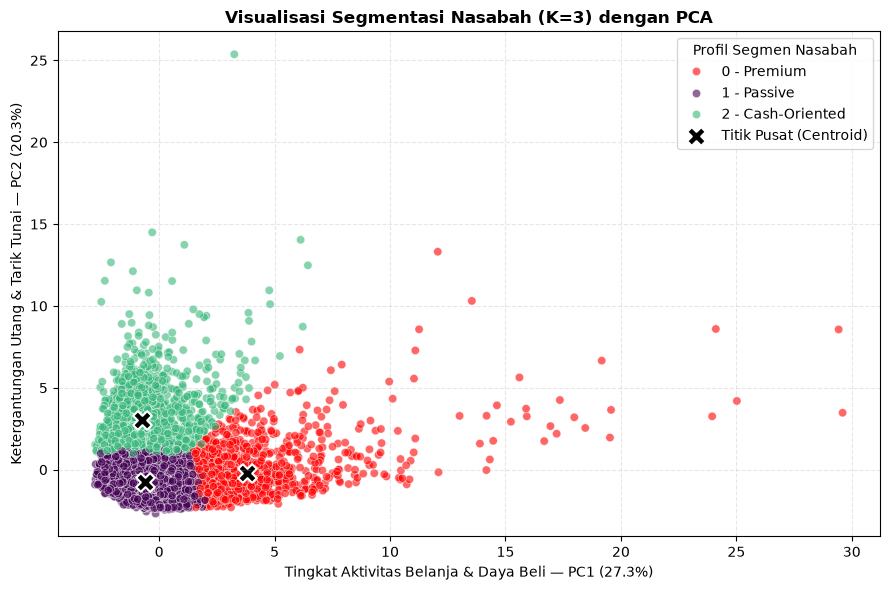

In [9]:
# Ganti n_clusters sesuai hasil terbaik dari Elbow/Silhouette yaitu 4
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans_final.fit_predict(X_scaled)

# Reduksi ke 2 dimensi untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Pemetaan nama profil bisnis untuk legenda
nama_cluster = {
    0: '0 - Premium',
    1: '1 - Passive',
    2: '2 - Cash-Oriented',
}

warna_cluster = {
    '0 - Premium': '#ff0000',           # Merah
    '1 - Passive': '#440154',           # Ungu
    '2 - Cash-Oriented': '#35b779',     # Hijau
}

# Hitung posisi titik pusat (centroid) dan persentase PCA
centroids_pca = pca.transform(kmeans_final.cluster_centers_)
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1], 
    hue=df_clean['Cluster'].map(nama_cluster), 
    hue_order=list(nama_cluster.values()),
    palette=warna_cluster, 
    alpha=0.6
)

# Menampilkan titik pusat (Centroid) tiap cluster
plt.scatter(
    centroids_pca[:, 0], 
    centroids_pca[:, 1], 
    c='black', 
    marker='X', 
    s=180, 
    edgecolor='white',
    linewidth=1.5,
    label='Titik Pusat (Centroid)'
)

plt.title(f'Visualisasi Segmentasi Nasabah (K={optimal_k}) dengan PCA', fontweight='bold')
plt.xlabel(f'Tingkat Aktivitas Belanja & Daya Beli — PC1 ({var_pc1:.1f}%)')
plt.ylabel(f'Ketergantungan Utang & Tarik Tunai — PC2 ({var_pc2:.1f}%)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Profil Segmen Nasabah')
plt.tight_layout()
plt.show()

In [10]:
# Melihat jumlah anggota per cluster
print(df_clean['Cluster'].value_counts())

# Melihat karakteristik rata-rata tiap cluster
cluster_profile = df_clean.groupby('Cluster').mean()
display(cluster_profile.T) # Di-transpose agar mudah dibaca ke bawah

Cluster
1    6114
2    1561
0    1275
Name: count, dtype: int64


Cluster,0,1,2
BALANCE,2182.352833,807.722510,4023.788865
BALANCE_FREQUENCY,0.981702,0.834577,0.959193
PURCHASES,4187.017796,496.062522,389.051448
ONEOFF_PURCHASES,2663.995153,247.273214,252.333261
INSTALLMENTS_PURCHASES,1523.493231,249.110368,136.797412
CASH_ADVANCE,449.753140,338.996760,3917.254973
PURCHASES_FREQUENCY,0.948175,0.460353,0.233899
ONEOFF_PURCHASES_FREQUENCY,0.664780,0.129191,0.111806
PURCHASES_INSTALLMENTS_FREQUENCY,0.739630,0.342052,0.145661
CASH_ADVANCE_FREQUENCY,0.062415,0.069563,0.451410


#### Berdasarkan Output Visualisasi dan karakteristik rata-rata, tiap cluster menunjukkan perilaku :
##### Kluster 0 (Warna Ungu)   : Kelompok nasabah kelas pasif/minimalis dengan aktivitas transaksi rendah di semua aspek. Contohnya jarang belanja, jarang tarik tunai, memiliki limit kredit terkecil, dan menggunakan kartu kredit sesekali saja.
##### Kluster 1 (Warna Merah)  : Kelompok nasabah kelas sultan/high-spender VIP dengan volume belanja tinggi, kapasitas kredit tinggi, sering bertransaksi, limit kredit tertinggi, dan paling disiplin membayar tagihan
##### Kluster 2 (Warna Hijau)  : Kelompok nasabah kelas rendah (Be-U) dengan nominal tarik tunai tertinggi, sisa utang kredit tinggi tetapi nominal belanja kecil, dan rasio pelunasan penuh yang rendah

In [11]:
import json

# 1. Jalankan K-Means (K=3) dan PCA (2 komponen) langsung pada X_scaled
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans_3.fit_predict(X_scaled)

pca_2 = PCA(n_components=2, random_state=42)
X_pca = pca_2.fit_transform(X_scaled)
centroids_pca = pca_2.transform(kmeans_3.cluster_centers_)

# 2. Gabungkan hasil kluster & koordinat PCA ke dataframe satuan asli (df_clean)
df_export = df_clean.copy()
df_export.insert(0, 'CUST_ID', df.loc[df_clean.index, 'CUST_ID'])
df_export['CLUSTER'] = cluster_labels
df_export['PCA_1'] = np.round(X_pca[:, 0], 4)
df_export['PCA_2'] = np.round(X_pca[:, 1], 4)

feature_cols = list(df_clean.columns)

# 3. Hitung profil statistik tiap kluster dalam satuan asli
cluster_profiles = []
for c in range(3):
    subset = df_export[df_export['CLUSTER'] == c]
    cluster_profiles.append({
        "cluster": int(c),
        "count": int(len(subset)),
        "percentage": round(float(len(subset) / len(df_export) * 100), 2),
        "centroid_pca": {
            "x": round(float(centroids_pca[c, 0]), 4),
            "y": round(float(centroids_pca[c, 1]), 4)
        },
        "mean_features": {col: round(float(subset[col].mean()), 2) for col in feature_cols},
        "median_features": {col: round(float(subset[col].median()), 2) for col in feature_cols}
    })

# 4. Susun struktur JSON lengkap
output_json = {
    "metadata": {
        "n_clusters": 3,
        "total_customers": int(len(df_export)),
        "preprocessing": "StandardScaler",
        "features": feature_cols,
        "pca_explained_variance": [round(float(v), 4) for v in pca_2.explained_variance_ratio_]
    },
    "model_params": {
        "scaler_mean": [round(float(x), 6) for x in scaler.mean_],
        "scaler_scale": [round(float(x), 6) for x in scaler.scale_],
        "centroids_scaled": [[round(float(val), 6) for val in row] for row in kmeans_3.cluster_centers_],
        "pca_components": [[round(float(val), 6) for val in row] for row in pca_2.components_],
        "pca_mean": [round(float(x), 6) for x in pca_2.mean_]
    },
    "cluster_profiles": cluster_profiles,
    "customers": json.loads(df_export.round(4).to_json(orient='records'))
}

# 5. Simpan ke file JSON
nama_file = 'hasil_clustering_3_kluster.json'
with open(nama_file, 'w', encoding='utf-8') as f:
    json.dump(output_json, f, indent=2)

print(f"Berhasil mengekspor '{nama_file}' dengan {len(df_export)} data nasabah.")

Berhasil mengekspor 'hasil_clustering_3_kluster.json' dengan 8950 data nasabah.
